# Laboratory 2

## 1.4

### 1. (1D) Minimize $f(x)=x^4-4x^2+x$

Derivatives:

$$f'(x)=4x^3-8x+1,\qquad f''(x)=12x^2-8.$$

The critical points are the roots of $4x^3-8x+1=0$ (the polynomial has no rational roots, so they are computed numerically). The second-derivative test classifies each one: $f''>0$ local minimum, $f''<0$ local maximum.

The global minimum is the lowest of the local minima.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

f   = lambda x: x**4 - 4*x**2 + x
fp  = lambda x: 4*x**3 - 8*x + 1
fpp = lambda x: 12*x**2 - 8

roots = np.sort(np.roots([4, 0, -8, 1]).real)

print(f"{'x*':>12} {'f(x*)':>12} {'f\'\'(x*)':>12}   classification")
for r in roots:
    kind = "local minimum" if fpp(r) > 0 else "local maximum"
    print(f"{r:12.6f} {f(r):12.6f} {fpp(r):12.6f}   {kind}")

x_global = roots[np.argmin(f(roots))]
print(f"\nGlobal minimum: x* = {x_global:.6f}, f(x*) = {f(x_global):.6f}")

          x*        f(x*)      f''(x*)   classification
   -1.472998    -5.444192    18.036663   local minimum
    0.126000     0.062748    -7.809487   local maximum
    1.346997    -2.618556    13.772824   local minimum

Global minimum: x* = -1.472998, f(x*) = -5.444192


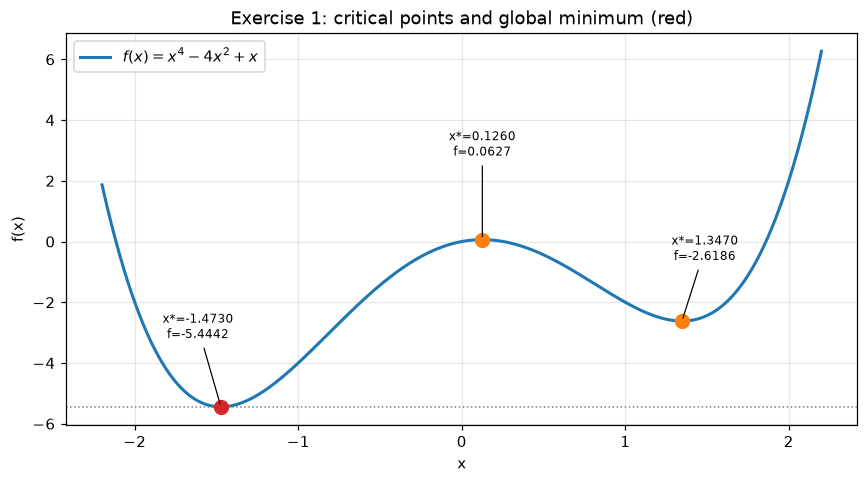

In [ ]:
xs = np.linspace(-2.2, 2.2, 800)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(xs, f(xs), lw=2, label=r"$f(x)=x^4-4x^2+x$")

offsets = [(-15, 45), (0, 55), (15, 40)]
for r, off in zip(roots, offsets):
    ax.scatter(r, f(r), s=80, zorder=3,
                color="tab:red" if r == x_global else "tab:orange")
    ax.annotate(f"x*={r:.4f}\nf={f(r):.4f}", (r, f(r)),
                textcoords="offset points", xytext=off, ha="center",
                fontsize=8, arrowprops=dict(arrowstyle="-", lw=0.8))

ax.axhline(f(x_global), ls=":", color="gray", lw=1)
ax.set_xlabel("x"); ax.set_ylabel("f(x)")
ax.set_title("Exercise 1: critical points and global minimum (red)")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

### 2. (2D) Minimize $f(x,y)=x^2+xy+y^2-4x-6y$

Gradient:

$$\nabla f(x,y)=\begin{bmatrix}2x+y-4\\ x+2y-6\end{bmatrix}.$$

Solving $\nabla f=0$:

$$\begin{cases}2x+y=4\\ x+2y=6\end{cases}\;\Longrightarrow\;(x^*,y^*)=\left(\tfrac{2}{3},\tfrac{8}{3}\right).$$

Hessian (constant):

$$H=\begin{bmatrix}2&1\\1&2\end{bmatrix},\qquad \lambda_1=1,\ \lambda_2=3>0.$$

$H$ is positive definite on all of $\mathbb{R}^2$, so the critical point is a strict local minimum and, since $f$ is a convex quadratic, it is also the **global minimum**. Minimum value: $f(2/3,8/3)=-28/3\approx-9.3333$.

In [3]:
grad = lambda x, y: np.array([2*x + y - 4, x + 2*y - 6])
f2   = lambda x, y: x**2 + x*y + y**2 - 4*x - 6*y

H = np.array([[2.0, 1.0], [1.0, 2.0]])
p = np.linalg.solve(H, np.array([4.0, 6.0]))

print("Critical point (x*, y*) =", p)
print("∇f(x*, y*) =", grad(*p))
print("Hessian:\n", H)
print("Eigenvalues:", np.linalg.eigvalsh(H))
print("D = f_xx f_yy - f_xy² =", np.linalg.det(H))
print(f"f(x*, y*) = {f2(*p):.6f}")

Critical point (x*, y*) = [0.66666667 2.66666667]
∇f(x*, y*) = [0. 0.]
Hessian:
 [[2. 1.]
 [1. 2.]]
Eigenvalues: [1. 3.]
D = f_xx f_yy - f_xy² = 2.9999999999999996
f(x*, y*) = -9.333333


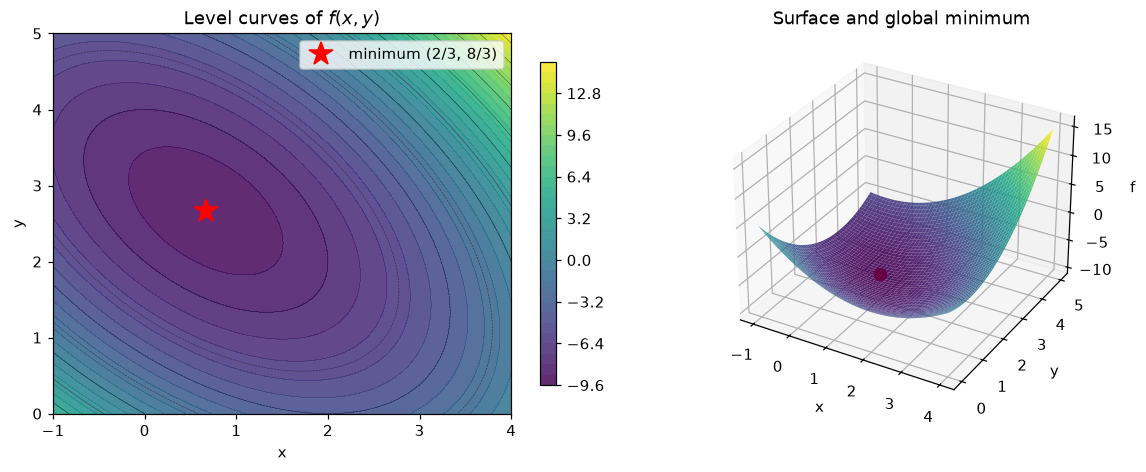

In [4]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

gx, gy = np.meshgrid(np.linspace(-1, 4, 150), np.linspace(0, 5, 150))
gz = f2(gx, gy)

fig = plt.figure(figsize=(11, 4.4))

ax1 = fig.add_subplot(1, 2, 1)
cf = ax1.contourf(gx, gy, gz, levels=30, cmap="viridis", alpha=0.85)
ax1.contour(gx, gy, gz, levels=15, colors="k", linewidths=0.4, alpha=0.5)
ax1.plot(*p, "r*", ms=16, label=r"minimum $(2/3,\,8/3)$")
ax1.set_xlabel("x"); ax1.set_ylabel("y")
ax1.set_title("Level curves of $f(x,y)$")
ax1.legend(); fig.colorbar(cf, ax=ax1, shrink=0.85)

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_surface(gx, gy, gz, cmap="viridis", alpha=0.9, linewidth=0)
ax2.scatter(*p, f2(*p), color="red", s=60, zorder=5)
ax2.set_xlabel("x"); ax2.set_ylabel("y"); ax2.set_zlabel("f")
ax2.set_title("Surface and global minimum")

plt.tight_layout(); plt.show()

## Brief conclusions

- **1D:** there are three critical points: two local minima ($x\approx-1.4730$ and $x\approx1.3470$) and one local maximum ($x\approx0.1260$). The global minimum is $x^*\approx-1.4730$ with $f(x^*)\approx-5.4442$, since the function grows to $+\infty$ at both ends.
- **2D:** the only critical point is $(2/3,\,8/3)$; the constant positive-definite Hessian guarantees that it is the global minimum, with $f_{\min}=-28/3$.

---

## 2.2 Python exercise: pseudoinverse vs `lstsq`

### ¿Qué problema estamos resolviendo?

Imagina que un vector desconocido $x_{true}$ produce mediciones $y$ mediante una matriz $A$:

$$y = A x_{true} + ruido.$$

Con ruido, normalmente no existe un vector que cumpla exactamente $Ax=y$. Buscamos entonces una estimación $\hat{x}$ cuya predicción $A\hat{x}$ quede lo más cerca posible de las mediciones:

$$\hat{x}=\operatorname*{argmin}_x \|Ax-y\|_2^2.$$

La cantidad $\|Ax-y\|_2$ es la longitud del **residuo**: la diferencia entre las mediciones predichas y las observadas. Al elevarla al cuadrado no cambia qué solución la minimiza.

Vamos a obtener esa estimación de dos maneras:

- `np.linalg.pinv(A) @ y` calcula la pseudoinversa de Moore–Penrose y la multiplica por $y$.
- `np.linalg.lstsq(A, y, rcond=None)[0]` le pide directamente a NumPy la solución de mínimos cuadrados. `[0]` selecciona el vector estimado de los resultados que devuelve la función.

En este ejercicio ambas formas deben dar prácticamente el mismo vector. `lstsq` suele ser la opción directa al resolver el problema; `pinv` ayuda a conectar el cálculo con la pseudoinversa.

### ¿Qué significan $m>n$ y $m<n$?

La matriz $A$ tiene tamaño $(m,n)$: tiene $m$ filas (mediciones) y $n$ columnas (coeficientes desconocidos).

- **$m>n$ (sobredeterminado):** hay más mediciones que incógnitas. Si las columnas de $A$ son independientes, hay una única mejor solución de mínimos cuadrados. Como hay ruido, el residuo suele ser distinto de cero.
- **$m<n$ (subdeterminado):** hay menos mediciones que incógnitas. Muchas soluciones pueden producir las mismas mediciones, así que los datos no bastan para identificar el vector original. `pinv` y `lstsq` escogen la solución de menor longitud, llamada **solución de norma mínima**.

El experimento crea un $x_{true}$ conocido, genera mediciones ruidosas y compara cuánto se acerca cada estimación a ese vector y cuánto se ajusta a las mediciones. Aquí conocemos la respuesta verdadera porque es una simulación; en un problema real normalmente no la conocemos.


In [5]:
import numpy as np
import matplotlib.pyplot as plt

SIGMA = 0.05


def run_case(m, n, seed):
    # La semilla fija hace que el ejemplo aleatorio se pueda repetir.
    rng = np.random.default_rng(seed)

    # Construimos una matriz aleatoria y una respuesta verdadera conocida.
    A = rng.standard_normal((m, n))
    x_true = rng.standard_normal(n)
    # Las mediciones son A @ x_true más ruido aleatorio.
    y = A @ x_true + SIGMA * rng.standard_normal(m)

    # Resolvemos el mismo problema con dos rutinas de NumPy.
    x_pinv = np.linalg.pinv(A) @ y
    x_lstsq = np.linalg.lstsq(A, y, rcond=None)[0]

    def relative_error(x):
        # Error relativo de coeficientes: 0 significa recuperación perfecta.
        return np.linalg.norm(x - x_true) / np.linalg.norm(x_true)

    def residual(x):
        # Desajuste de mediciones: longitud de A @ estimación - y.
        return np.linalg.norm(A @ x - y)

    return {
        "m": m, "n": n,
        "A": A, "x_true": x_true, "y": y,
        "x_pinv": x_pinv, "x_lstsq": x_lstsq,
        "rel_pinv": relative_error(x_pinv),
        "rel_lstsq": relative_error(x_lstsq),
        "res_pinv": residual(x_pinv),
        "res_lstsq": residual(x_lstsq),
    }


cases = {
    "m > n": run_case(80, 20, seed=1),
    "m < n": run_case(20, 80, seed=2),
}

print(f"{'case':<6} {'method':<8} {'rel. error':>12} {'residual':>12}")
print("-" * 42)
for name, r in cases.items():
    print(f"{name:<6} {'pinv':<8} {r['rel_pinv']:12.3e} {r['res_pinv']:12.3e}")
    print(f"{'':<6} {'lstsq':<8} {r['rel_lstsq']:12.3e} {r['res_lstsq']:12.3e}")

print("\nMaximum difference between pinv and lstsq:")
for name, r in cases.items():
    diff = np.linalg.norm(r["x_pinv"] - r["x_lstsq"])
    print(f"  {name}: {diff:.2e}")

case   method     rel. error     residual
------------------------------------------
m > n  pinv        4.471e-03    4.148e-01
       lstsq       4.471e-03    4.148e-01
m < n  pinv        8.928e-01    4.759e-14
       lstsq       8.928e-01    4.578e-14

Maximum difference between pinv and lstsq:
  m > n: 1.01e-14
  m < n: 5.46e-15


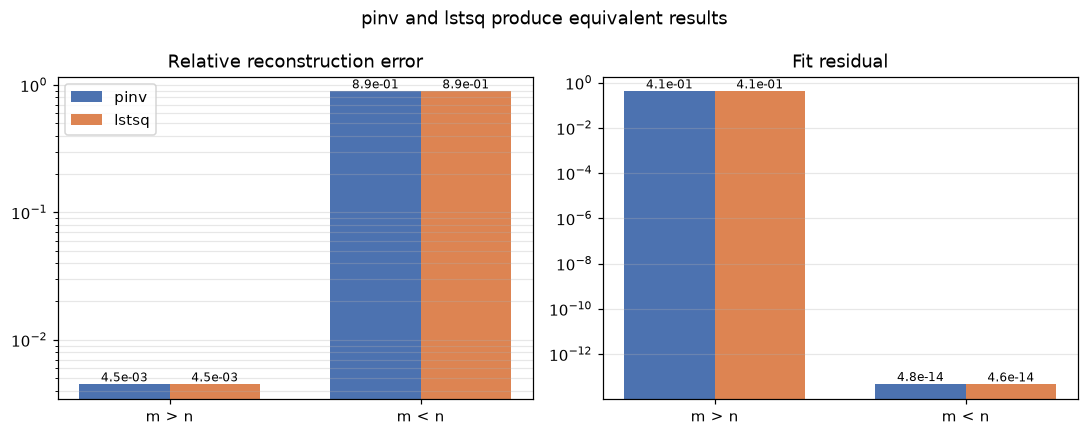

In [ ]:
names = list(cases.keys())
pos = np.arange(len(names))
width = 0.36

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, key, title in zip(
    axes,
    ["rel", "res"],
    ["Relative reconstruction error", "Fit residual"],
):
    values_pinv = [cases[k][key + "_pinv"] for k in names]
    values_lstsq = [cases[k][key + "_lstsq"] for k in names]

    ax.bar(pos - width / 2, values_pinv, width,
            label="pinv", color="#4C72B0")
    ax.bar(pos + width / 2, values_lstsq, width,
            label="lstsq", color="#DD8452")

    ax.set_xticks(pos, ["m > n", "m < n"])
    # La escala logarítmica permite comparar valores muy distintos.
    ax.set_yscale("log")
    ax.set_title(title)
    ax.grid(axis="y", which="both", alpha=0.3)

    for x, v in zip(pos - width / 2, values_pinv):
        ax.text(x, v, f"{v:.1e}", ha="center", va="bottom", fontsize=8)
    for x, v in zip(pos + width / 2, values_lstsq):
        ax.text(x, v, f"{v:.1e}", ha="center", va="bottom", fontsize=8)

axes[0].legend()
fig.suptitle("pinv and lstsq produce equivalent results")
fig.tight_layout()
plt.show()


**Cómo leer esta figura:** cada grupo compara azul (`pinv`) y naranja (`lstsq`) para una forma de matriz. El panel izquierdo muestra el error relativo; el derecho, el residuo. El eje vertical es logarítmico: subir un paso equivale a multiplicar el valor, no a sumarle una cantidad fija. Barras de altura casi igual indican que los dos métodos coinciden. En el caso $m<n$ pueden ocurrir a la vez un residuo minúsculo y un error relativo grande: ajustar bien las mediciones no garantiza recuperar los coeficientes verdaderos.


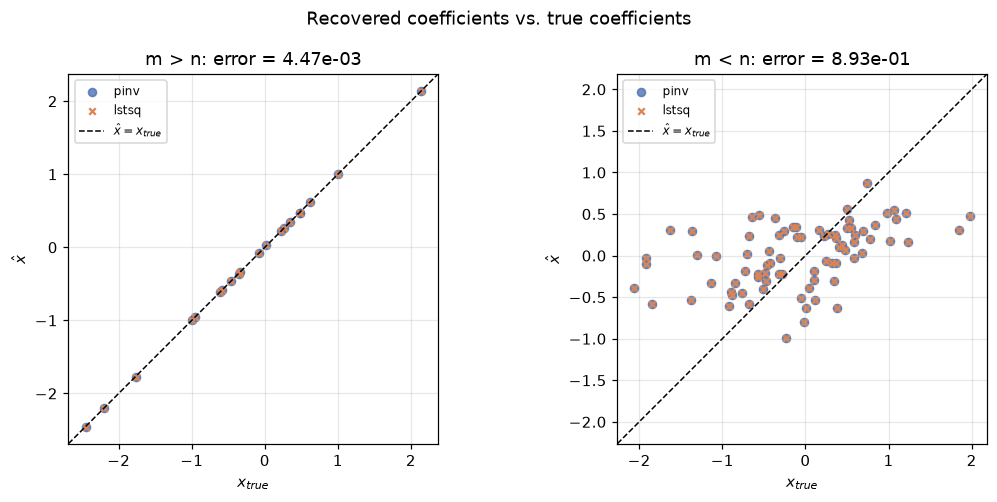

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))

for ax, (name, r) in zip(axes, cases.items()):
    ax.scatter(r["x_true"], r["x_pinv"], s=28, alpha=0.8,
                label="pinv", color="#4C72B0")
    ax.scatter(r["x_true"], r["x_lstsq"], s=18, marker="x",
                label="lstsq", color="#DD8452")

    minimum = min(r["x_true"].min(), r["x_pinv"].min(), r["x_lstsq"].min())
    maximum = max(r["x_true"].max(), r["x_pinv"].max(), r["x_lstsq"].max())
    margin = 0.05 * (maximum - minimum)

    ax.plot([minimum - margin, maximum + margin],
            [minimum - margin, maximum + margin],
            "k--", lw=1, label=r"$\hat{x}=x_{true}$")

    ax.set_xlim(minimum - margin, maximum + margin)
    ax.set_ylim(minimum - margin, maximum + margin)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(r"$x_{true}$")
    ax.set_ylabel(r"$\hat{x}$")
    ax.set_title(f"{name}: error = {r['rel_pinv']:.2e}")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left")

fig.suptitle("Recovered coefficients vs. true coefficients")
fig.tight_layout()
plt.show()




---

## 3.1 Ejercicio: deconvolución e inestabilidad

### ¿Qué queremos hacer?

Tenemos una imagen original $X$, la desenfocamos y observamos una versión $y$. El modelo es

$$y=Ax+e,$$

- $x$ es la imagen guardada como un vector largo (`X.ravel()`).
- $A$ es el operador de blur: transforma la imagen en su versión borrosa.
- $e$ es ruido que se agrega a la medición.
- $y$ es la imagen borrosa que observamos (posiblemente con ruido).

Aplicar el blur es el **problema directo**. Recuperar la imagen original desde la imagen borrosa es la **deconvolución** o problema inverso. Primero probaremos la pseudoinversa con datos limpios y con ruido para ver por qué invertir un blur puede ser inestable.

### Datos y operador de blur

Usamos una imagen gris de $48\times48$ píxeles, escalada al rango [0,1], y un kernel Gaussiano de $9\times9$ con `sigma=1.5`. En los bordes usamos reflexión (`boundary="symm"`).

Construimos la matriz $A$ aplicando el blur a imágenes de prueba con un solo píxel encendido. Cada resultado es una columna de $A$. Esto permite representar el blur como una multiplicación de matrices, aunque construir y almacenar esa matriz es costoso; por eso usamos una imagen pequeña.


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d
from skimage import data, transform
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# Preparar la imagen: escala de grises, tamaño pequeño e intensidades entre 0 y 1.
X = data.camera().astype(float) / 255.0
X = transform.resize(X, (48, 48), anti_aliasing=True)
X = X / X.max()

h, w = X.shape           # alto y ancho de la imagen
N = h * w                # cantidad total de píxeles
print(f"Imagen: {h}x{w} = {N} píxeles; rango [{X.min():.2f}, {X.max():.2f}]")


def gaussian_kernel(size=9, sigma=1.5):
    """Crear un kernel Gaussiano normalizado (los pesos suman 1)."""
    radius = size // 2
    coords = np.arange(-radius, radius + 1)
    xx, yy = np.meshgrid(coords, coords)
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    return kernel / kernel.sum()


K = gaussian_kernel(size=9, sigma=1.5)


def blur_image(image):
    """Aplicar el blur sin cambiar el tamaño de la imagen."""
    return convolve2d(image, K, mode="same", boundary="symm")


# Construir A: cada columna es el blur de una imagen con un solo píxel encendido.
A = np.empty((N, N))
for pixel_index in range(N):
    impulse = np.zeros((h, w))
    impulse.flat[pixel_index] = 1.0
    A[:, pixel_index] = blur_image(impulse).ravel()

print(f"Forma de A: {A.shape}; número de entradas: {A.size:,}")
print(f"Error de simetría max|A-A.T|: {np.abs(A - A.T).max():.2e}")
print(f"Suma de los pesos del kernel: {K.sum():.6f}")


Image: 48x48 = 2304 pixels, range [0.02, 1.00]
A: (2304, 2304), 5,308,416 entries, 169,744 nonzeros
Symmetry error max|A - A^T| = 2.78e-17
Kernel sum = 1.000000



Cada columna de $A$ muestra cómo un píxel puntual se reparte entre sus vecinos al desenfocarlo. Una vez construida $A$, el blur completo de la imagen se calcula como `A @ x`.

### ¿Por qué usamos SVD para calcular la pseudoinversa?

La SVD descompone la matriz como $A=U\Sigma V^\top$. A partir de ella se obtiene la pseudoinversa $A^\dagger=V\Sigma^{-1}U^\top$, que es justamente la operación de `np.linalg.pinv(A)`.

La calculamos una sola vez porque en esta sección aplicamos la pseudoinversa muchas veces (varios datos y varios niveles de ruido). Reutilizar la SVD evita repetir ese cálculo pesado. También nos da los valores singulares, que usaremos para explicar por qué el ruido se amplifica. Así que **la reconstrucción es con la pseudoinversa; la SVD es una forma eficiente de calcularla y estudiar la inestabilidad**.


In [9]:
# Factorizar A una sola vez. NumPy devuelve A = U @ diag(s) @ Vt.
# Reutilizaremos estos factores para invertir varios vectores de mediciones.
U, s, Vt = np.linalg.svd(A, full_matrices=False)


def pseudoinverse_apply(measurements):
    """Calcular A^dagger @ measurements usando la SVD ya calculada."""
    # U.T @ measurements: expresar los datos en las direcciones de U.
    # Dividir por s: invertir el efecto del blur en cada dirección.
    # Vt.T @ ...: volver a las coordenadas de los píxeles.
    return Vt.T @ ((U.T @ measurements) / s)


# Vector original y medición borrosa sin ruido.
x = X.ravel()
y = A @ x

# Experimento 1: agregar ruido a la medición DESPUÉS del blur.
SIGMA_ETA = 0.005
rng = np.random.default_rng(1)  # semilla fija: resultados reproducibles
noise = SIGMA_ETA * rng.standard_normal(N)
y_noisy = y + noise

# Aplicar la pseudoinversa a datos limpios y a datos ruidosos.
x_recovered_clean = pseudoinverse_apply(y)
x_recovered_noisy = pseudoinverse_apply(y_noisy)

# Experimento 2: agregar el mismo ruido a la imagen ANTES del blur.
x_noisy_before_blur = x + noise
y_from_noisy_image = A @ x_noisy_before_blur
x_recovered_before_blur = pseudoinverse_apply(y_from_noisy_image)

# Resumen numérico de cuánto se altera cada caso.
print(f"Número de condición de A: {s[0] / s[-1]:.2e}")
print(f"Error relativo agregado a y: {np.linalg.norm(noise) / np.linalg.norm(y):.3e}")
print(f"Amplificación al invertir ruido en y: "
      f"{np.linalg.norm(x_recovered_noisy - x) / np.linalg.norm(noise):.2e}x")
print(f"Error máximo, caso limpio: "
      f"{np.max(np.abs(x_recovered_clean - x)):.2e}")
print(f"Error máximo, ruido antes del blur: "
      f"{np.max(np.abs(x_recovered_before_blur - x_noisy_before_blur)):.2e}")

# Comparar métricas de calidad contra la imagen original.
examples = [
    ("medición borrosa y", y),
    ("pseudoinversa, limpio", x_recovered_clean),
    ("medición con ruido", y_noisy),
    ("pseudoinversa, ruidoso", x_recovered_noisy),
    ("imagen original + ruido", x_noisy_before_blur),
    ("invertir ruido pre-blur", x_recovered_before_blur),
]
print(f"\n{'Resultado':27s} {'PSNR (dB)':>10s} {'SSIM':>7s}")
print("-" * 47)
for label, vector in examples:
    image = vector.reshape(h, w)
    score_psnr = psnr(X, image, data_range=1.0)
    score_ssim = ssim(X, image, data_range=1.0)
    print(f"{label:27s} {score_psnr:10.2f} {score_ssim:7.3f}")


cond(A) = 2.44e+08   (sigma_max = 1.000, sigma_min = 4.09e-09)
relative data error ||e||/||y|| = 7.962e-03
amplification ||x_noisy - x|| / ||e|| = 4.38e+06
max |pinv(A(x+e)) - (x+e)| = 1.25e-09
max |pinv(Ax) - x|         = 1.73e-09

reconstruction              PSNR (dB)    SSIM
----------------------------------------------
blurred measurement y           23.49   0.812
pinv(y), noiseless             187.72   1.000
noisy measurement y+e           23.45   0.804
pinv(y+e)                      -86.90   0.000
image with noise x+e            45.94   0.993
pinv(A(x+e))                    45.94   0.993


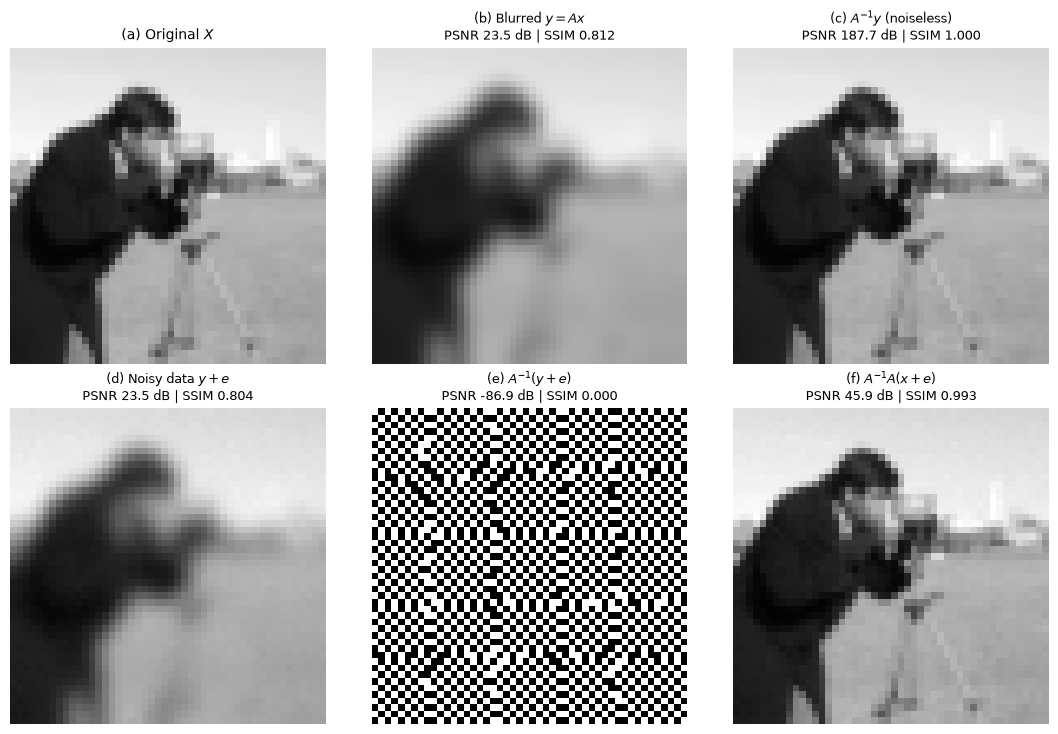

In [10]:
# Preparar los seis paneles de la comparación.
panels = [
    ("(a) Original", X, None),
    ("(b) Blur sin ruido: y=Ax", y.reshape(h, w), y),
    ("(c) pinv(A) @ y", x_recovered_clean.reshape(h, w), x_recovered_clean),
    ("(d) Medición con ruido: y+e", y_noisy.reshape(h, w), y_noisy),
    ("(e) pinv(A) @ (y+e)", x_recovered_noisy.reshape(h, w), x_recovered_noisy),
    ("(f) Ruido antes del blur", x_recovered_before_blur.reshape(h, w),
     x_recovered_before_blur),
]

fig, axes = plt.subplots(2, 3, figsize=(11, 7.4))
for ax, (title, image, vector) in zip(axes.ravel(), panels):
    # El recorte solo afecta la visualización; no modifica los cálculos ni las métricas.
    ax.imshow(np.clip(image, 0, 1), cmap="gray", vmin=0, vmax=1)
    if vector is None:
        ax.set_title(title, fontsize=10)
    else:
        image_vector = vector.reshape(h, w)
        score_psnr = psnr(X, image_vector, data_range=1.0)
        score_ssim = ssim(X, image_vector, data_range=1.0)
        ax.set_title(f"{title}\nPSNR {score_psnr:.1f} dB | SSIM {score_ssim:.3f}",
                     fontsize=9)
    ax.axis("off")

fig.tight_layout()



**Figura 1: cómo leerla.** Los seis cuadros comparan la imagen original, las mediciones borrosas y las reconstrucciones con la pseudoinversa. PSNR y SSIM son medidas de parecido con la imagen original: un valor mayor suele indicar mejor reconstrucción.

- **(a)** Imagen original, usada como referencia.
- **(b)** Imagen después del blur, sin ruido.
- **(c)** Resultado de aplicar la pseudoinversa a datos limpios: recupera casi toda la imagen.
- **(d)** Medición borrosa con ruido agregado después del blur. El ruido es pequeño y casi no se distingue aquí.
- **(e)** Reconstrucción de (d): el ruido se amplifica y domina el resultado. El recorte a [0,1] es solo para mostrar la imagen; las métricas usan los valores sin recortar.
- **(f)** Control: se agregó ruido a la imagen antes del blur. Al invertir, se recupera la imagen con aproximadamente ese mismo ruido.

La comparación más importante es **(e) frente a (f)**: la pseudoinversa amplifica mucho el ruido cuando este se añade después del desenfoque.



### 3. ¿Por qué se amplifica el ruido?

El blur reduce mucho ciertos detalles de la imagen. Al deshacerlo, la pseudoinversa debe amplificar esas direcciones débiles. El problema es que también amplifica el ruido que se encuentre en ellas.

La SVD ayuda a verlo: $A=U\Sigma V^\top$, y los elementos de la diagonal $s_i$ de $\Sigma$ indican cuánto conserva el blur cada dirección. Para invertir, dividimos por $s_i$. Si $s_i$ es muy pequeño, dividir por él magnifica cualquier error. El número de condición $s_{max}/s_{min}$ resume el peor caso de esa amplificación.

No es necesario conocer SVD para usar `np.linalg.pinv`; aquí la mostramos para explicar por qué la pseudoinversa es inestable en este problema.


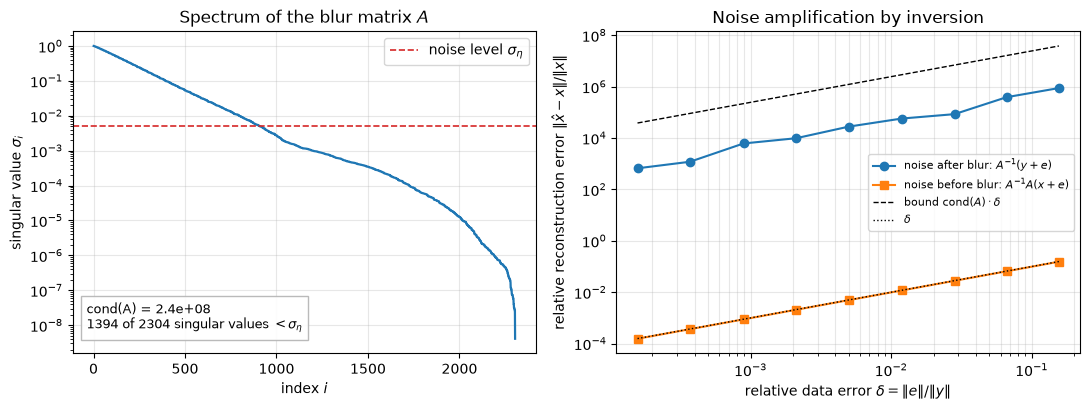

In [11]:
fig, (ax_spectrum, ax_noise) = plt.subplots(1, 2, figsize=(11, 4.3))

# Panel izquierdo: valores singulares de mayor a menor.
indices = np.arange(1, N + 1)
ax_spectrum.semilogy(indices, s, lw=1.5)
ax_spectrum.axhline(SIGMA_ETA, color="tab:red", ls="--",
                    label="desviación del ruido agregado")
ax_spectrum.set_xlabel("índice (valores ordenados de mayor a menor)")
ax_spectrum.set_ylabel("valor singular")
ax_spectrum.set_title("Qué tan fuerte conserva A cada dirección")
ax_spectrum.grid(alpha=0.3)
ax_spectrum.legend(fontsize=8)
small_count = np.sum(s < SIGMA_ETA)
ax_spectrum.text(0.03, 0.06,
                 f"cond(A) = {s[0] / s[-1]:.1e}\n"
                 f"{small_count} de {N} valores bajo el nivel de ruido",
                 transform=ax_spectrum.transAxes, fontsize=8, va="bottom",
                 bbox=dict(fc="white", ec="0.7", alpha=0.9))

# Panel derecho: repetir con varios tamaños de ruido y comparar los errores.
noise_levels = np.logspace(-4, -1, 9)
repetitions = 5
relative_data_error = np.zeros((repetitions, len(noise_levels)))
relative_error_after = np.zeros_like(relative_data_error)
relative_error_before = np.zeros_like(relative_data_error)
rng_sweep = np.random.default_rng(7)

for level_index, noise_std in enumerate(noise_levels):
    for repetition in range(repetitions):
        trial_noise = noise_std * rng_sweep.standard_normal(N)
        relative_data_error[repetition, level_index] = (
            np.linalg.norm(trial_noise) / np.linalg.norm(y)
        )
        estimate_after = pseudoinverse_apply(y + trial_noise)
        estimate_before = pseudoinverse_apply(A @ (x + trial_noise))
        relative_error_after[repetition, level_index] = (
            np.linalg.norm(estimate_after - x) / np.linalg.norm(x)
        )
        relative_error_before[repetition, level_index] = (
            np.linalg.norm(estimate_before - x) / np.linalg.norm(x)
        )

mean_data_error = relative_data_error.mean(axis=0)
ax_noise.loglog(mean_data_error, relative_error_after.mean(axis=0), "o-",
                label="ruido agregado después del blur")
ax_noise.loglog(mean_data_error, relative_error_before.mean(axis=0), "s-",
                label="ruido agregado antes del blur")
ax_noise.loglog(mean_data_error, mean_data_error, "k:",
                label="referencia: sin amplificación")
ax_noise.set_xlabel("error relativo en las mediciones")
ax_noise.set_ylabel("error relativo en la imagen estimada")
ax_noise.set_title("Error de reconstrucción al cambiar el ruido")
ax_noise.grid(alpha=0.3, which="both")
ax_noise.legend(fontsize=8)

fig.tight_layout()



**Figura 2: cómo leerla.**

- **Izquierda:** cada punto es un valor singular. Los más pequeños están abajo; al invertir, se divide por ellos y el ruido puede crecer mucho. La línea roja indica la desviación estándar del ruido usado en el primer experimento.
- **Derecha:** el eje horizontal mide el error relativo de las mediciones y el vertical el error relativo de la imagen reconstruida. Ambos ejes son logarítmicos. La diagonal punteada representa una referencia en la que el error no se amplifica. La curva de ruido agregado después del blur queda muy por encima: la pseudoinversa amplifica ese ruido. El ruido agregado antes del blur se mantiene cerca de la referencia. Cada punto promedia cinco realizaciones aleatorias.

**Idea clave:** el blur oculta detalles; la pseudoinversa intenta recuperarlos, pero también amplifica el ruido que ocupa esas mismas direcciones.



### Conclusiones

1. **La pseudoinversa recupera la imagen cuando no hay ruido**, con un error numérico muy pequeño.
2. **Con ruido agregado a la medición borrosa, la reconstrucción puede ser muy mala.** La pseudoinversa amplifica perturbaciones que el blur hizo difíciles de distinguir.
3. **La posición del ruido importa:** al agregarlo antes del blur, el caso ideal se comporta como recuperar la imagen original más ese mismo ruido.
4. La pseudoinversa es útil para mostrar el problema, pero en imágenes reales con ruido normalmente hace falta regularización, tema que se desarrolla en las secciones posteriores.



---

## 4.3 Ejercicio: quitar ruido al desenfocar usando una prioridad dispersa

En la sección 3.1 vimos que invertir el blur directamente amplifica el ruido. Ahora añadiremos una idea extra sobre cómo suelen ser las imágenes naturales: aunque tengan muchos píxeles, se pueden describir con pocos coeficientes wavelet grandes y muchos pequeños. A esta propiedad la llamamos **dispersidad** (sparsity) en la base wavelet.

Buscamos una imagen estimada $\hat{x}$ que cumpla dos objetivos:

$$\hat{x}=\arg\min_x \underbrace{\frac{1}{2}\|Ax-y_\eta\|_2^2}_{\text{ajustar los datos}}+\lambda\underbrace{\|Wx\|_1}_{\text{favorecer pocos coeficientes wavelet grandes}}.$$

- El primer término pide que al desenfocar la estimación, $A\hat{x}$ se parezca a la medición ruidosa $y_\eta$.
- $W$ transforma la imagen a coeficientes wavelet. $\|Wx\|_1$ suma sus valores absolutos y favorece que muchos sean pequeños o cero.
- $\lambda$ controla el equilibrio: más grande elimina más coeficientes (y ruido), pero también puede borrar detalles.

Usamos **ISTA**, un algoritmo que repite dos pasos: primero corrige la imagen para que sus datos borrosos se acerquen a la medición; después aplica un umbral suave a los coeficientes wavelet pequeños. El umbral conserva los coeficientes grandes, asociados con estructura y bordes, y reduce los pequeños, que a menudo son ruido.


orthonormality: | ||Wv|| - ||v|| | = 7.1e-15, max|W^-1 W v - v| = 1.6e-15
coefficients for 95% of the energy: 38 of 2304
coefficients for 99% of the energy: 163 of 2304
fraction of coefficients with |c| < 1e-3: 16.1%
L = ||A^T A||_2 ~ 0.9912, step eta = 1/L = 1.0089


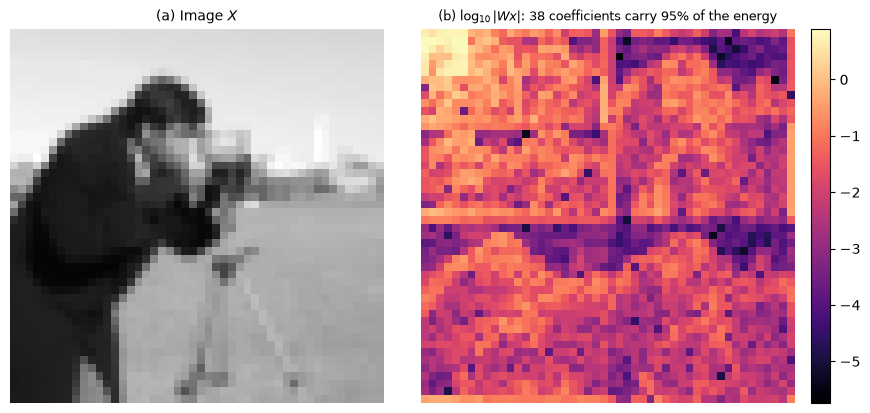

In [9]:
import pywt

# W convierte la imagen en coeficientes wavelet; Winv vuelve a la imagen.
# db2 es la familia wavelet y usamos tres niveles de descomposición.
WAVELET, LEVEL = "db2", 3
coeffs = pywt.wavedec2(X, wavelet=WAVELET, level=LEVEL, mode="periodization")
coeff_arr, coeff_slices = pywt.coeffs_to_array(coeffs)


def W(z):
    """Convertir un vector de píxeles a vector de coeficientes wavelet."""
    C = pywt.wavedec2(z.reshape(h, w), wavelet=WAVELET, level=LEVEL,
                        mode="periodization")
    return pywt.coeffs_to_array(C)[0].ravel()


def Winv(u):
    """Reconstruir el vector de píxeles desde los coeficientes wavelet."""
    C = pywt.array_to_coeffs(u.reshape(coeff_arr.shape), coeff_slices,
                                output_format="wavedec2")
    return pywt.waverec2(C, wavelet=WAVELET, mode="periodization").ravel()


# Comprobar que W conserva la longitud y que Winv deshace W.
v = np.random.default_rng(0).standard_normal(N)
print(f"orthonormality: | ||Wv|| - ||v|| | = "
        f"{abs(np.linalg.norm(W(v)) - np.linalg.norm(v)):.1e}, "
        f"max|W^-1 W v - v| = {np.abs(Winv(W(v)) - v).max():.1e}")

# Comprobar dispersidad: ¿cuántos coeficientes concentran la energía de la imagen?
c = W(x)
energy = np.sort(c**2)[::-1]
cum = np.cumsum(energy) / energy.sum()
print(f"coefficients for 95% of the energy: {np.searchsorted(cum, 0.95) + 1} of {N}")
print(f"coefficients for 99% of the energy: {np.searchsorted(cum, 0.99) + 1} of {N}")
print(f"fraction of coefficients with |c| < 1e-3: {np.mean(np.abs(c) < 1e-3):.1%}")


# Calcular L, una escala del problema, con iteración de potencias.
# El tamaño de paso eta=1/L ayuda a que las actualizaciones de ISTA sean estables.
def power_iteration(M, n_iter=60):
    v = np.random.default_rng(1).standard_normal(M.shape[1])
    v /= np.linalg.norm(v)
    for _ in range(n_iter):
        v = M.T @ (M @ v)
        v /= np.linalg.norm(v)
    return v @ (M.T @ (M @ v))


L = power_iteration(A)
eta = 1.0 / L
print(f"L = ||A^T A||_2 ~ {L:.4f}, step eta = 1/L = {eta:.4f}")


def soft(u, alpha):
    """Reducir coeficientes pequeños hacia cero y dejar en cero los menores que alpha."""
    return np.sign(u) * np.maximum(np.abs(u) - alpha, 0.0)


# Comparar la imagen original con el tamaño de sus coeficientes wavelet.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4.2))

ax1.imshow(X, cmap="gray", vmin=0, vmax=1)
ax1.set_title("(a) Image $X$", fontsize=10)
ax1.axis("off")

# El logaritmo deja ver juntos coeficientes grandes y muy pequeños.
im = ax2.imshow(np.log10(np.abs(coeff_arr) + 1e-6), cmap="magma")
ax2.set_title(f"(b) $\\log_{{10}}|Wx|$: {np.searchsorted(cum, 0.95) + 1} "
                f"coefficients carry 95% of the energy", fontsize=9)
ax2.axis("off")
fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

fig.tight_layout()



**Figura 4: cómo leerla.** A la izquierda está la imagen. A la derecha se muestran los valores absolutos de sus coeficientes wavelet en escala logarítmica (por eso se ven tanto los grandes como los pequeños). Las zonas más brillantes corresponden a coeficientes de mayor magnitud.

La gráfica y los números impresos indican que una fracción pequeña de los coeficientes concentra gran parte de la energía de la imagen. Esto justifica la prioridad dispersa: podemos intentar eliminar coeficientes wavelet pequeños para reducir ruido y conservar los grandes que representan la estructura principal.

### 2. Elegir la fuerza de regularización $\lambda$

Probamos varios valores de $\lambda$ y ejecutamos ISTA durante 250 iteraciones para cada uno. Comparamos las reconstrucciones con la imagen original usando PSNR y SSIM. En un problema real normalmente no conocemos la imagen original; aquí podemos usarla porque estamos haciendo un experimento controlado.


In [10]:
def ista(lam, n_iter, track=False):
    """Resolver el modelo con ISTA para un lambda y número de iteraciones dados."""
    # Empezar desde una imagen completamente negra (todos los píxeles cero).
    xk = np.zeros(N)
    hist = {"it": [], "psnr": [], "ssim": [], "obj": []}
    best = {"it": 0, "psnr": -np.inf, "ssim": 0.0, "x": None}

    for it in range(1, n_iter + 1):
        # Paso 1: medir el error de predicción A@xk - y_eta y corregir xk.
        # A.T lleva esa corrección desde el espacio de mediciones al de imágenes.
        z = xk - eta * (A.T @ (A @ xk - y_eta))
        # Paso 2: pasar a wavelets, encoger coeficientes pequeños y volver a píxeles.
        xk = Winv(soft(W(z), eta * lam))

        # Guardar métricas cada 10 pasos solo cuando queremos seguir la evolución.
        if track and (it == 1 or it % 10 == 0):
            r = A @ xk - y_eta
            p = psnr(X, xk.reshape(h, w), data_range=1.0)
            q = ssim(X, xk.reshape(h, w), data_range=1.0)
            hist["it"].append(it)
            hist["psnr"].append(p)
            hist["ssim"].append(q)
            # Objetivo que ISTA intenta minimizar: error de datos + penalización wavelet.
            hist["obj"].append(0.5 * r @ r + lam * np.abs(W(xk)).sum())
            # Guardar también la iteración con mejor PSNR para esta simulación.
            if p > best["psnr"]:
                best = {"it": it, "psnr": p, "ssim": q, "x": xk.copy()}

    return xk, hist, best


# Valores de lambda: recorremos desde regularización débil hasta fuerte.
LAMBDAS = np.array([1e-5, 2e-5, 3e-5, 5e-5, 1e-4, 3e-4, 1e-3])
N_ITER_SWEEP = 250

# Ejecutar cada configuración y guardar calidad final de la reconstrucción.
sweep = []
for lam in LAMBDAS:
    xh, _, _ = ista(lam, N_ITER_SWEEP)
    sweep.append((lam,
                    psnr(X, xh.reshape(h, w), data_range=1.0),
                    ssim(X, xh.reshape(h, w), data_range=1.0)))

print(f"{'lambda':>8s} {'PSNR (dB)':>10s} {'SSIM':>7s}")
print("-" * 28)
for lam, p, q in sweep:
    print(f"{lam:8.0e} {p:10.2f} {q:7.3f}")

best_lam = max(sweep, key=lambda row: row[1])[0]
print(f"\nBest lambda by PSNR: {best_lam:.1e}")


  lambda  PSNR (dB)    SSIM
----------------------------
   1e-05      28.05   0.874
   2e-05      28.05   0.877
   3e-05      28.05   0.879
   5e-05      28.02   0.883
   1e-04      27.85   0.886
   3e-04      26.98   0.877
   1e-03      25.58   0.853

Best lambda by PSNR: 2.0e-05



**Qué nos dice esta comparación:** con $\lambda$ muy pequeño, el algoritmo apenas penaliza los coeficientes pequeños y queda más ruido. Al aumentar $\lambda$, se quita más ruido, pero si es demasiado grande también desaparecen texturas y detalles. El mejor valor ofrece un equilibrio. PSNR mide error promedio de píxeles; SSIM se fija más en la similitud de estructura, así que sus mejores valores no necesariamente coinciden.

### 3. Elegir cuándo detener ISTA

Fijamos el $\lambda$ que dio mejor PSNR en la prueba anterior y observamos el algoritmo durante más iteraciones. Guardamos la calidad de la imagen y el valor del objetivo cada 10 iteraciones. Esto permite ver algo importante: el objetivo puede seguir bajando aunque la similitud con la imagen verdadera ya haya empezado a empeorar.


ISTA: lambda = 2.0e-05
best iteration =  260   PSNR = 28.05 dB   SSIM = 0.876
last iterate (1500 iterations): PSNR = 26.17 dB, SSIM = 0.752


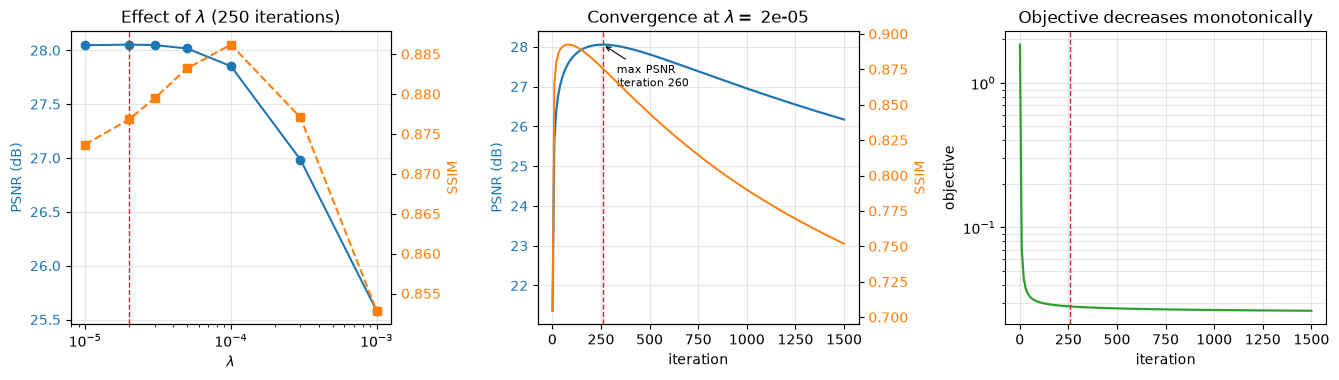

In [11]:
# Seguir la optimización durante más pasos para observar su evolución.
N_ITER_MAX = 1500
x_last, hist, best = ista(best_lam, N_ITER_MAX, track=True)

# best contiene la reconstrucción con mejor PSNR observada durante la ejecución.
best_it = best["it"]
x_ista = best["x"]

print(f"ISTA: lambda = {best_lam:.1e}")
print(f"best iteration = {best_it:4d}   PSNR = {best['psnr']:.2f} dB   "
      f"SSIM = {best['ssim']:.3f}")
print(f"last iterate ({N_ITER_MAX} iterations): "
      f"PSNR = {hist['psnr'][-1]:.2f} dB, SSIM = {hist['ssim'][-1]:.3f}")

lams_sweep = np.array([row[0] for row in sweep])
psnr_sweep = np.array([row[1] for row in sweep])
ssim_sweep = np.array([row[2] for row in sweep])

# Tres paneles: efecto de lambda, calidad durante las iteraciones y objetivo.
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))

# (a) Cada curva muestra cómo PSNR y SSIM cambian con lambda.
ax = axes[0]
ax.semilogx(lams_sweep, psnr_sweep, "o-", color="tab:blue")
ax.axvline(best_lam, color="tab:red", ls="--", lw=1)
ax.set_xlabel(r"$\lambda$")
ax.set_ylabel("PSNR (dB)", color="tab:blue")
ax.tick_params(axis="y", labelcolor="tab:blue")
ax.grid(alpha=0.3)
ax.set_title(r"Effect of $\lambda$ (250 iterations)")
ax_b = ax.twinx()
ax_b.semilogx(lams_sweep, ssim_sweep, "s--", color="tab:orange")
ax_b.set_ylabel("SSIM", color="tab:orange")
ax_b.tick_params(axis="y", labelcolor="tab:orange")

# (b) Ver si la imagen sigue mejorando mientras avanzan las iteraciones.
ax = axes[1]
ax.plot(hist["it"], hist["psnr"], color="tab:blue", lw=1.6)
ax.axvline(best_it, color="tab:red", ls="--", lw=1)
ax.set_xlabel("iteration")
ax.set_ylabel("PSNR (dB)", color="tab:blue")
ax.tick_params(axis="y", labelcolor="tab:blue")
ax.grid(alpha=0.3)
ax.set_title(r"Convergence at $\lambda=$" + f" {best_lam:.0e}")
ax_b = ax.twinx()
ax_b.plot(hist["it"], hist["ssim"], color="tab:orange", lw=1.4)
ax_b.set_ylabel("SSIM", color="tab:orange")
ax_b.tick_params(axis="y", labelcolor="tab:orange")
ax.annotate(f"max PSNR\niteration {best_it}", (best_it, best["psnr"]),
            textcoords="offset points", xytext=(10, -30), fontsize=8,
            arrowprops=dict(arrowstyle="->", lw=0.8))

# (c) El objetivo matemático que ISTA minimiza debe ir disminuyendo.
ax = axes[2]
ax.semilogy(hist["it"], hist["obj"], color="tab:green", lw=1.6)
ax.axvline(best_it, color="tab:red", ls="--", lw=1)
ax.set_xlabel("iteration")
ax.set_ylabel("objective")
ax.set_title("Objective decreases monotonically")
ax.grid(alpha=0.3, which="both")

fig.tight_layout()



**Figura 5: cómo leerla.**

- **Panel (a):** calidad frente a $\lambda$ después de 250 iteraciones. Azul = PSNR; naranja = SSIM. La línea vertical roja indica el $\lambda$ elegido por PSNR. Las métricas pueden preferir valores ligeramente distintos porque miden aspectos diferentes.
- **Panel (b):** PSNR y SSIM durante las iteraciones, usando ese $\lambda$. La línea roja marca la iteración con mayor PSNR. Si la calidad baja después, significa que más iteraciones están ajustando detalles del ruido.
- **Panel (c):** valor del objetivo que ISTA minimiza. Que siga bajando significa que el algoritmo optimiza su fórmula, pero no garantiza que la imagen se parezca cada vez más a la verdadera.

Por eso detener el algoritmo temprano también ayuda a regularizar: no siempre conviene ejecutar el mayor número posible de iteraciones. El mejor $\lambda$ y la mejor iteración se identifican usando la imagen original conocida; con datos reales habría que elegirlos sin esa referencia.



### 4. Comparison with the linear reconstructions

We now compare ISTA at its best configuration against the methods of Section 3.1: the blurred data, the direct pseudoinverse, Tikhonov and TSVD.


method                    PSNR (dB)    SSIM
--------------------------------------------
blurred measurement           23.49   0.812
direct inversion             -86.90   0.000
ISTA, 10 iterations           25.64   0.865
ISTA, 260 iterations          28.05   0.876


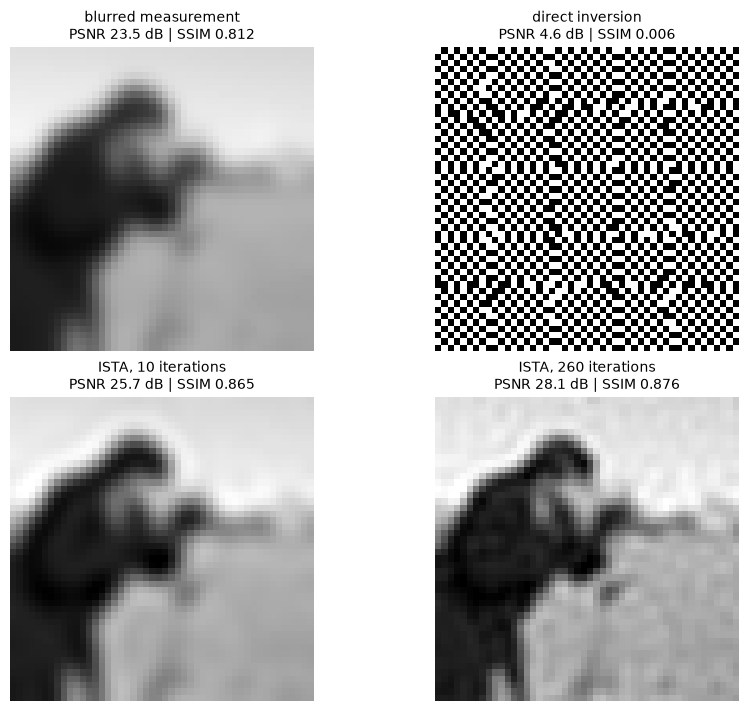

In [15]:
xh10, _, _ = ista(best_lam, 10)

methods = [
    ("blurred measurement", y),
    ("direct inversion", x_noisy),
    ("ISTA, 10 iterations", xh10),
    (f"ISTA, {best_it} iterations", x_ista),
]

print(f"{'method':24s} {'PSNR (dB)':>10s} {'SSIM':>7s}")
print("-" * 44)
for name, z in methods:
    Z = z.reshape(h, w)
    print(f"{name:24s} {psnr(X, Z, data_range=1.0):10.2f} "
            f"{ssim(X, Z, data_range=1.0):7.3f}")

# Arrange the four reconstructions in a compact 2 x 2 grid
fig, axes = plt.subplots(2, 2, figsize=(8.5, 7), constrained_layout=True)

for ax, (name, z) in zip(axes.ravel(), methods):
    image = np.clip(z.reshape(h, w), 0, 1)
    ax.imshow(image, cmap="gray", vmin=0, vmax=1,
                interpolation="nearest", aspect="equal")

    p = psnr(X, image, data_range=1.0)
    q = ssim(X, image, data_range=1.0)
    ax.set_title(f"{name}\nPSNR {p:.1f} dB | SSIM {q:.3f}", fontsize=10)
    ax.axis("off")



**Figure 6.** From top-left to bottom-right: the blurred measurement, the unstable direct inversion, the best Tikhonov and TSVD reconstructions, ISTA after only 10 iterations, and ISTA at its best iteration. ISTA removes most of the noise of the linear reconstructions while keeping the main edges; the residual error is mostly the information that the blur destroyed.

### Conclusions for this exercise

1. **Without a prior, the inversion amplifies noise.** The direct pseudoinverse gives PSNR $-86.9$ dB; Tikhonov and TSVD stabilize it but still leave a noisy, ringy image. The wavelet prior suppresses most of that noise because it forces the solution to be sparse in a basis where the image is concentrated in a few coefficients.
2. **Soft-thresholding is the prior in action.** Small wavelet coefficients are dominated by noise and are set to zero; large coefficients carry edges and texture and are only shrunk by $\eta\lambda$. That is why the reconstruction keeps structure while removing high-frequency noise.
3. **$\lambda$ controls the bias-variance tradeoff.** Too small ($\lesssim10^{-5}$) leaves noise; too large ($\gtrsim3\times10^{-4}$) over-smooths and erases texture. PSNR is flat over a decade of useful values, while SSIM prefers slightly stronger regularization.
4. **Iterations also regularize.** The objective decreases monotonically, but PSNR peaks at about 260 iterations and then declines (26.2 dB at 1500). Solving the model too accurately overfits the noise, so early stopping is a second regularization knob. A faster alternative is FISTA, which reaches a similar point in far fewer iterations.
5. **The gain over Tikhonov is real but modest.** ISTA reaches $28.05$ dB and SSIM $0.876$, against $27.87$ dB and $0.853$ for Tikhonov and $27.17$ dB and $0.790$ for TSVD. Since 1394 singular directions are already below the noise level, no method can recover that information; the prior improves the structure, not the missing frequencies.
6. **Other priors.** A total-variation prior would favor piecewise-smooth images and preserve sharp edges better, at the cost of a more involved proximal step (Chambolle's algorithm) and possible staircasing. Learned priors (denoisers, networks) can capture richer image statistics than a fixed wavelet basis.
